# D5. 딥러닝 오디오 분류 + 미니 프로젝트: Speech Commands 키워드 인식

**음성 AI 전문가 과정 (160h) | 1주차 M1 | 4시간**

## 학습 목표
1. **Speech Commands** 데이터셋의 구성(1초 · 16 kHz · 35단어 · 화자 기준 분할)을 이해하고 `torchaudio`로 내려받아 다룬다.
2. 1초 음성을 D3의 **Log-Mel (1 × 64 × 101)** 로 바꿔 `Dataset` · `DataLoader`로 묶는다.
3. **CNN**의 합성곱 · 풀링 · 출력 크기 · 파라미터 수, **softmax**와 **cross-entropy**를 수식으로 설명하고 모델을 직접 만든다.
4. **학습 루프**(forward → loss → backward → step)를 직접 작성하고 학습 곡선, 정확도, **혼동 행렬**로 평가한다.
5. **SpecAugment**로 성능을 개선하고, 내 음성 파일을 넣어 키워드를 맞히는 `predict_keyword()`를 완성한다 (미니 프로젝트).

## 오늘의 실습 흐름
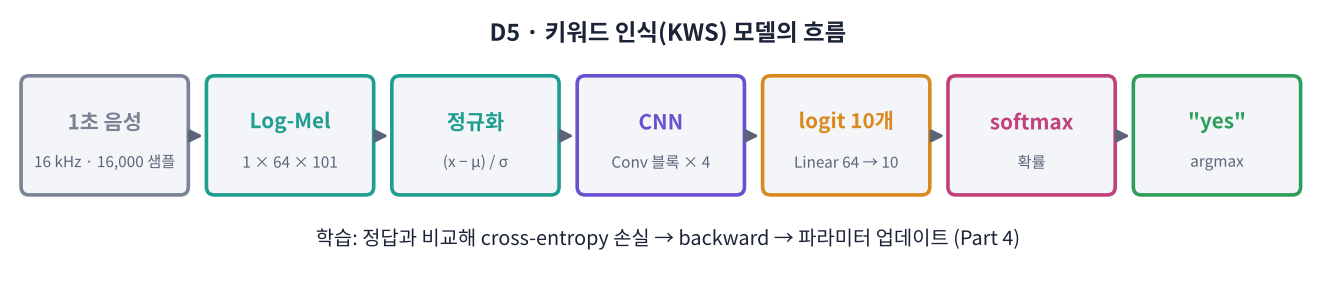

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | 데이터셋 내려받기 · 화자 분할, 1초 맞추기, Log-Mel 특징, Dataset · DataLoader | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | CNN 원리: 합성곱 · 출력 크기 · 파라미터, softmax · cross-entropy, 모델 만들기 | Part 3, 워크시트 2교시 |
| 3교시 | 학습 루프, 학습 곡선, 테스트 정확도, 혼동 행렬 | Part 4 ~ 5, 워크시트 3교시 |
| 4교시 | SpecAugment, 미니 프로젝트 `predict_keyword()`, 모델 저장 | Part 6 ~ 7, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day05/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day05/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다.
- 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 📐 **수식으로 보기**에서 원리를 수식으로 정리하고, ▶️ **수식 검증** 셀에서 예측값과 측정값을 비교합니다. 🔍 **코드 해설**은 주요 코드를 한 줄씩 설명합니다.

> ⚙️ **오늘은 GPU 런타임을 권장합니다.** [런타임] → [런타임 유형 변경] → **T4 GPU**. GPU가 없어도 돌아가도록 CPU에서는 데이터 양과 epoch를 자동으로 줄입니다.
>
> 📦 데이터셋(약 2.3 GB)을 내려받고 푸는 데 Colab에서 2~4분 걸립니다. **Part 0을 수업 시작하자마자 실행**해 두세요.

> 🎬 **애니메이션 D5-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#flow) — Part 1~6 로드맵

## Part 0. 준비

GPU 확인, 패키지 설치, 데이터셋 다운로드를 먼저 시작합니다. Colab에는 `torch`와 `torchaudio`가 이미 설치되어 있으므로 **따로 설치하지 않습니다** (버전이 어긋나면 import 오류가 납니다).

In [ ]:
!pip install -q gTTS soundfile
print("✅ 설치 완료")

In [ ]:
import os, time, random
import numpy as np
import soundfile as sf
import librosa, librosa.display
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from IPython.display import Audio, display

SR = 16000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0); random.seed(0)

# GPU가 없으면 데이터와 학습량을 줄여 수업 시간 안에 끝나게
MAX_TRAIN = 1500 if DEVICE == "cuda" else 400      # 단어당 학습 샘플 수
MAX_EVAL  = 300  if DEVICE == "cuda" else 100      # 단어당 검증 · 테스트 샘플 수
EPOCHS    = 12   if DEVICE == "cuda" else 5

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

print(f"torch {torch.__version__} | torchaudio {torchaudio.__version__} | device = {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else " (GPU 없음 → 축소 설정)"))
print(f"설정: 단어당 학습 {MAX_TRAIN}개, 검증 · 테스트 {MAX_EVAL}개, {EPOCHS} epoch")

In [ ]:
# Speech Commands v0.02 내려받기 (약 2.3 GB, 처음 한 번만) — torchaudio 데이터셋 클래스 사용
os.makedirs("data", exist_ok=True)
t0 = time.time()
train_meta = torchaudio.datasets.SPEECHCOMMANDS("data", download=True, subset="training")
val_meta   = torchaudio.datasets.SPEECHCOMMANDS("data", download=True, subset="validation")
test_meta  = torchaudio.datasets.SPEECHCOMMANDS("data", download=True, subset="testing")
print(f"완료 ({time.time() - t0:.0f}초) | 학습 {len(train_meta):,} · 검증 {len(val_meta):,} · 테스트 {len(test_meta):,}개")
print("예시 메타데이터:", train_meta.get_metadata(0))

#### 🔍 코드 해설: torchaudio.datasets.SPEECHCOMMANDS

| 코드 | 하는 일 |
|---|---|
| `SPEECHCOMMANDS("data", download=True, subset="training")` | `data/` 아래에 내려받아 풀고, 공식 목록(`validation_list.txt`, `testing_list.txt`)으로 학습 · 검증 · 테스트를 나눔. 이미 있으면 다시 받지 않음 |
| `get_metadata(i)` | (상대 경로, 샘플링 레이트, **단어**, **화자 ID**, 발화 번호). 오디오는 읽지 않아서 빠름 |
| `ds[i]` | (파형, 16000, 단어, 화자, 번호). 내부적으로 `torchaudio.load`를 씀 |

> 💡 torchaudio 2.9부터 오디오 읽기 · 쓰기(`torchaudio.load`)는 **TorchCodec**으로 옮겨 가는 중이라 환경에 따라 별도 설치가 필요할 수 있습니다. 그래서 오늘은 데이터셋 클래스로 **목록과 경로만** 얻고, 파일은 D2부터 써 온 `soundfile`로 직접 읽습니다. 특징 추출(`torchaudio.transforms`)은 그대로 torchaudio를 씁니다.

## Part 1. Speech Commands 데이터셋

**Speech Commands**(Google, 2018)는 키워드 인식(KWS, Keyword Spotting)의 대표 데이터셋입니다. "Hey Siri", "OK Google"처럼 **짧은 단어 하나를 알아듣는** 문제를 연습하기 좋습니다.

| 항목 | 값 |
|---|---|
| 단어 수 | 35개 (yes, no, up, down, left, right, on, off, stop, go, 숫자 0~9, 기타 단어) |
| 클립 | 약 10만 5천 개, **1초 이하**, 16 kHz, mono WAV |
| 화자 | 2,600명 이상의 자원봉사자가 각자 녹음 |
| 분할 | 화자 ID의 해시로 **학습 80 · 검증 10 · 테스트 10** |

오늘은 그중 대표 **10개 키워드**만 골라 10-class 분류기를 만듭니다.

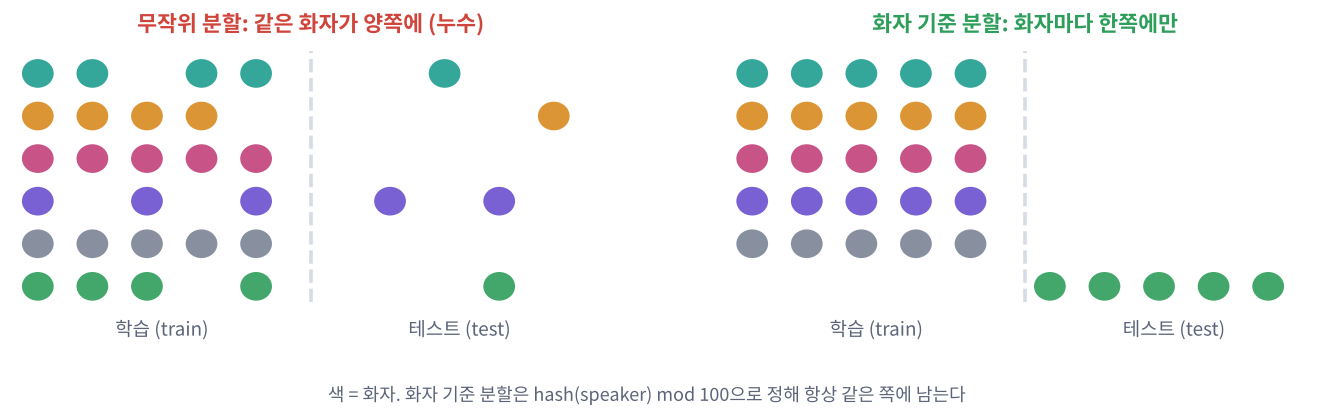

### 1-1. 📐 수식으로 보기: 화자 기준 분할

같은 사람의 목소리가 학습과 테스트에 동시에 들어가면, 모델이 **단어가 아니라 목소리를 외워서** 맞힐 수 있습니다. 실제로는 처음 듣는 사람의 목소리를 알아들어야 하므로, **화자 단위로** 나눕니다.

$$
\text{split}(\text{speaker}) =
\begin{cases}
\text{validation} & h \bmod 100 < 10 \\
\text{testing} & 10 \le h \bmod 100 < 20 \\
\text{training} & \text{그 외}
\end{cases}
\qquad h = \text{hash}(\text{speaker ID})
$$

해시는 같은 입력에 항상 같은 값을 주므로, 데이터를 나중에 추가해도 **같은 화자는 항상 같은 쪽**에 남습니다. (공식 목록 파일이 이 규칙으로 만들어져 있습니다.)

> 🎬 **애니메이션 D5-2:** [데이터셋과 분할](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#data) — 화자 분할과 무작위 분할을 비교하고, 1초 맞추기(패딩 · 자르기) 보기

In [ ]:
from collections import Counter

KEYWORDS = ["yes", "no", "up", "down", "left", "right", "on", "off", "stop", "go"]
K2I = {k: i for i, k in enumerate(KEYWORDS)}

counts = Counter(train_meta.get_metadata(i)[2] for i in range(len(train_meta)))
words = sorted(counts, key=counts.get, reverse=True)
plt.figure(figsize=(14, 3))
plt.bar(words, [counts[w] for w in words], color=["tab:orange" if w in K2I else "tab:gray" for w in words])
plt.xticks(rotation=70); plt.ylabel("train clips"); plt.title("Speech Commands v0.02 (orange = today's 10 keywords)")
plt.tight_layout(); plt.show()
print("오늘 쓰는 10단어의 학습 클립 수:", {k: counts.get(k, 0) for k in KEYWORDS})

In [ ]:
def select(meta_ds, max_per_class, seed=0):
    # 10개 키워드만 골라 (파일 경로, 클래스 번호, 화자) 목록으로. 단어당 최대 max_per_class개
    rng = random.Random(seed)
    by_word = {k: [] for k in KEYWORDS}
    for i in range(len(meta_ds)):
        rel, _, word, spk, _ = meta_ds.get_metadata(i)
        if word in by_word:
            by_word[word].append((os.path.join(meta_ds._archive, rel), K2I[word], spk))
    items = []
    for k in KEYWORDS:
        rng.shuffle(by_word[k]); items += by_word[k][:max_per_class]
    rng.shuffle(items)
    return items

train_items = select(train_meta, MAX_TRAIN)
val_items   = select(val_meta, MAX_EVAL)
test_items  = select(test_meta, MAX_EVAL)
print(f"학습 {len(train_items):,} · 검증 {len(val_items):,} · 테스트 {len(test_items):,}개")

spk = {name: {s for _, _, s in it} for name, it in [("train", train_items), ("val", val_items), ("test", test_items)]}
print(f"화자 수: 학습 {len(spk['train'])} · 검증 {len(spk['val'])} · 테스트 {len(spk['test'])}")
print("학습 ∩ 테스트 화자:", len(spk["train"] & spk["test"]), "명 (0이어야 정상)")

### 1-2. 클립 길이를 1초로 맞추기

딥러닝 모델은 **같은 크기의 입력**을 묶어(batch) 한 번에 계산합니다. 그런데 Speech Commands 클립은 1초보다 짧은 것도 있습니다. 그래서 모든 클립을 정확히 **16,000 샘플**로 맞춥니다.

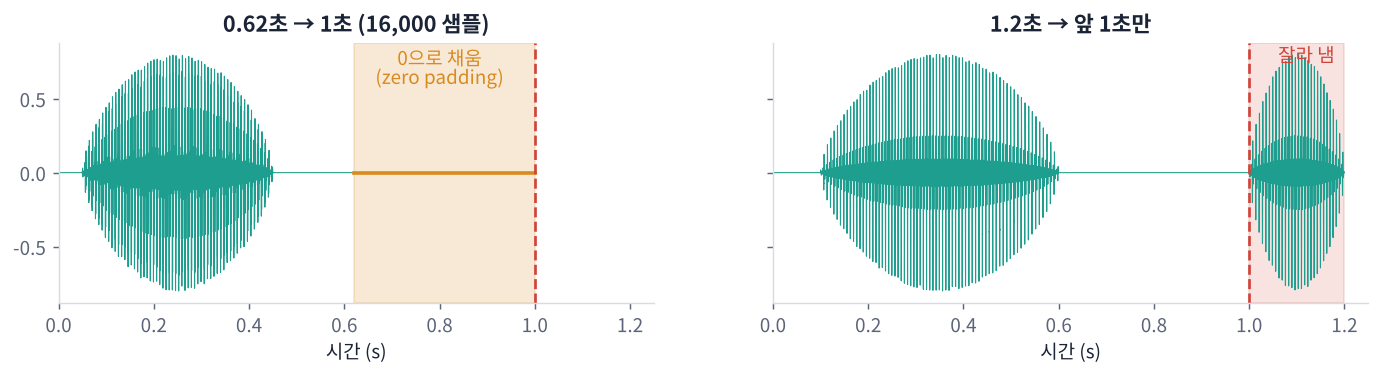

- 짧으면 → 뒤를 0으로 채움 (**zero padding**)
- 길면 → 앞에서 16,000개만 남김 (**자르기**)

### 🧩 빈칸 실습 1: pad_or_trim()
짧은 클립의 뒤를 0으로 채워 길이를 정확히 `n`으로 만드세요. `np.pad(y, (앞에 붙일 개수, 뒤에 붙일 개수))` 입니다.

In [ ]:
# 🧩 빈칸 실습 1
def pad_or_trim(y, n=SR):
    if len(y) >= n:
        return y[:n]
    return np.pad(y, (0, ____ - len(y)))

def load_1s(path):
    y, sr = sf.read(path, dtype="float32")
    assert sr == SR
    return pad_or_trim(y)

lengths = [sf.info(p).frames for p, _, _ in train_items[:500]]
print(f"원래 길이: 최소 {min(lengths)} · 최대 {max(lengths)} 샘플 | 1초 미만 {np.mean(np.array(lengths) < SR):.0%}")
for path, c, _ in train_items[:4]:
    y = load_1s(path)
    print(f"{KEYWORDS[c]:>5s}: {len(y)} 샘플"); display(Audio(y, rate=SR))
check(len(pad_or_trim(np.ones(9000))) == SR and len(pad_or_trim(np.ones(20000))) == SR, hint="목표 길이 n에서 지금 길이를 빼면 붙일 개수입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return np.pad(y, (0, n - len(y)))
```

**해설**: 9,000샘플 클립이면 뒤에 $16000 - 9000 = 7000$개의 0을 붙입니다. 앞에 붙이지 않는 이유는 Speech Commands가 단어를 대체로 클립 앞쪽에 담고 있어서입니다. 0은 '무음'이라 Log-Mel에서는 가장 어두운 값(바닥 dB)이 됩니다. 앞뒤를 반씩 나눠 붙이거나 무작위로 위치를 옮기는 방법도 있습니다 (Part 6의 time shift).

</details>

## Part 2. 특징: 1초 음성 → Log-Mel 이미지 (1 × 64 × 101)

D3에서 만든 Log-Mel을 그대로 씁니다. 이번에는 `torchaudio.transforms`로 만들어서 **GPU에서도 같은 코드로** 돌아가게 합니다.

### 2-1. 📐 수식으로 보기: 입력 모양

| 단계 | 설정 | 모양 |
|---|---|---|
| 파형 | 1초 · 16 kHz | $(1, 16000)$ |
| STFT | $N = 400$ (25 ms), $H = 160$ (10 ms), Hann | $(201, M)$ |
| Mel | `n_mels = 64` | $(64, M)$ |
| dB | $10\log_{10}$, 최대 − 80 dB 아래는 자름 | $(64, M)$ |
| CNN 입력 | 채널 1개를 앞에 | $(1, 64, M)$ |

프레임 수는 D3의 `center=True` 공식 그대로입니다.

$$
M = 1 + \left\lfloor \frac{L}{H} \right\rfloor = 1 + \left\lfloor \frac{16000}{160} \right\rfloor = 101
$$

그래서 1초 음성 하나는 **세로 64(주파수) × 가로 101(시간)** 짜리 흑백 이미지가 됩니다. 오늘의 CNN은 이 이미지를 보고 단어를 맞힙니다.

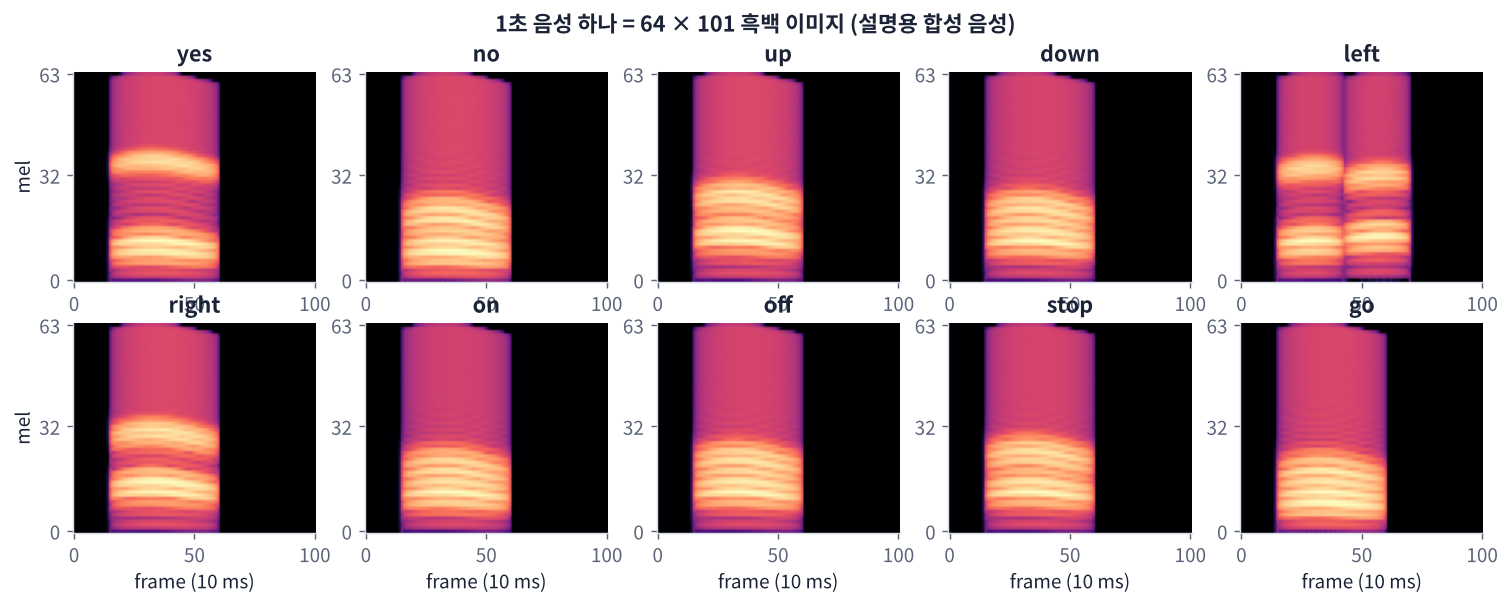

> 🎬 **애니메이션 D5-3:** [1초 음성 → Log-Mel](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#feature) — 키워드별 파형과 Log-Mel을 보고 듣기, n_mels · hop을 바꾸면 모양이 어떻게 바뀌는지

### 🧩 빈칸 실습 2: 프레임 수 예측하기
hop 길이를 채워 프레임 수 공식을 완성하고, torchaudio 결과와 같은지 확인하세요.

In [ ]:
# 🧩 빈칸 실습 2
N_MELS, N_FFT, HOP = 64, 400, 160
MEL = T.MelSpectrogram(sample_rate=SR, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
TO_DB = T.AmplitudeToDB(stype="power", top_db=80)

def wav2feat(y):
    x = torch.from_numpy(y).float().unsqueeze(0)        # (1, 16000)
    return TO_DB(MEL(x))                                # (1, 64, 101)

n_frames = 1 + SR // ____                               # center=True 공식
feat = wav2feat(load_1s(train_items[0][0]))
print("예측:", (1, N_MELS, n_frames), "| 실제:", tuple(feat.shape))

fig, axs = plt.subplots(2, 5, figsize=(15, 5))
shown = {}
for path, c, _ in train_items:
    if c not in shown: shown[c] = path
    if len(shown) == len(KEYWORDS): break
for ax, c in zip(axs.flat, range(len(KEYWORDS))):
    f = wav2feat(load_1s(shown[c]))[0]
    librosa.display.specshow(f.numpy(), sr=SR, hop_length=HOP, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(KEYWORDS[c]); ax.label_outer()
plt.tight_layout(); plt.show()
check(tuple(feat.shape) == (1, 64, 101) and n_frames == 101, hint="hop은 160샘플(10 ms)입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
n_frames = 1 + SR // HOP     # 1 + 16000 // 160 = 101
```

**해설**: 10 ms마다 한 프레임이고 `center=True`라 앞뒤로 반 창씩 덧대므로 $1 + 100 = 101$입니다. `MelSpectrogram`은 D3의 `librosa.feature.melspectrogram`과 같은 일(STFT → 파워 → mel 필터뱅크)을 하고, `AmplitudeToDB(stype='power')`가 $10\log_{10}$을 합니다. 단어마다 밝은 덩어리의 위치와 모양이 다른 것이 보이죠? CNN은 이 무늬를 학습합니다.

</details>

### 2-2. 특징을 미리 계산해 텐서로 만들기

학습은 같은 데이터를 여러 번(epoch) 봅니다. 매번 파일을 읽고 Log-Mel을 다시 계산하면 느리므로, **한 번만 계산해 메모리에 올려** 둡니다.

**정규화**: 학습 세트 전체의 평균 $\mu$와 표준편차 $\sigma$로 $\hat x = (x - \mu)/\sigma$. 입력의 크기가 0 근처로 모이면 학습이 안정됩니다. 검증 · 테스트 · 실제 예측에도 **학습 세트의 $\mu, \sigma$를 그대로** 씁니다.

In [ ]:
def build_features(items, name):
    t0 = time.time()
    X = torch.stack([wav2feat(load_1s(p)) for p, _, _ in items])     # (N, 1, 64, 101)
    y = torch.tensor([c for _, c, _ in items])
    print(f"{name:5s}: X {tuple(X.shape)}, y {tuple(y.shape)} ({time.time() - t0:.0f}초, {X.numel() * 4 / 1e6:.0f} MB)")
    return X, y

X_train, y_train = build_features(train_items, "train")
X_val,   y_val   = build_features(val_items, "val")
X_test,  y_test  = build_features(test_items, "test")

MU, SD = X_train.mean().item(), X_train.std().item()          # 학습 세트 기준 정규화 값
X_train, X_val, X_test = [(X - MU) / SD for X in (X_train, X_val, X_test)]
print(f"정규화: μ = {MU:.2f} dB, σ = {SD:.2f} dB → 학습 세트 평균 {X_train.mean():.3f}, 표준편차 {X_train.std():.3f}")

### 🧩 빈칸 실습 3: Dataset 클래스
PyTorch의 `Dataset`은 두 가지만 알려 주면 됩니다: **몇 개인가**(`__len__`)와 **i번째는 무엇인가**(`__getitem__`). i번째 특징과 정답을 함께 돌려주세요.

In [ ]:
# 🧩 빈칸 실습 3
class FeatDataset(Dataset):
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return ____, self.y[i]

BATCH = 128
train_loader = DataLoader(FeatDataset(X_train, y_train), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(FeatDataset(X_val, y_val), batch_size=256)
test_loader  = DataLoader(FeatDataset(X_test, y_test), batch_size=256)

xb, yb = next(iter(train_loader))
print("한 배치:", tuple(xb.shape), tuple(yb.shape), "| 배치 수:", len(train_loader))
check(tuple(xb.shape[1:]) == (1, 64, 101) and len(xb) == len(yb), hint="i번째 특징은 self.X[i]입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return self.X[i], self.y[i]
```

**해설**: `DataLoader`는 `__getitem__`을 `batch_size`번 불러 결과를 쌓아(stack) 한 배치로 만듭니다. 그래서 배치 모양이 $(128, 1, 64, 101)$, 정답은 $(128,)$입니다. `shuffle=True`는 epoch마다 순서를 섞어, 모델이 순서를 외우지 못하게 합니다. 검증 · 테스트는 섞을 필요가 없습니다.

</details>

#### 🔍 코드 해설: Dataset · DataLoader

| 코드 | 하는 일 |
|---|---|
| `torch.stack([...])` | (1, 64, 101) 텐서 N개를 쌓아 (N, 1, 64, 101) |
| `(X - MU) / SD` | 학습 세트의 평균 · 표준편차로 정규화. 검증 · 테스트에도 **같은 값** |
| `DataLoader(..., batch_size=128, shuffle=True)` | 128개씩 묶고, epoch마다 순서를 섞음 |
| `next(iter(train_loader))` | 첫 배치 하나만 꺼내 모양 확인 |

> 💡 오늘은 특징을 미리 계산해 두었기 때문에 Dataset이 단순합니다. 데이터가 커서 메모리에 다 안 들어가면 `__getitem__` 안에서 파일을 읽고 특징을 만드는 방식으로 바꾸고, `DataLoader(num_workers=2)`로 병렬로 읽습니다.

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day05/worksheet.html)** — Speech Commands 구성, 화자 기준 분할, 1초 맞추기, Log-Mel 모양 (1 × 64 × 101), 정규화, Dataset · DataLoader
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 3. CNN: 소리 이미지를 보는 신경망

Log-Mel은 이미지처럼 생겼으므로, 이미지 분류에 쓰는 **CNN**(Convolutional Neural Network)을 그대로 쓸 수 있습니다. CNN은 작은 **필터**(커널)를 이미지 위로 밀며 무늬를 찾습니다. 앞쪽 층은 짧은 선 · 점 같은 작은 무늬를, 뒤쪽 층은 그것들을 조합한 큰 무늬(포먼트의 움직임, 음절 모양)를 찾습니다.

### 3-1. 📐 수식으로 보기: 합성곱, 출력 크기, 파라미터 수

**합성곱**(2D, 채널 $C_{in} \to C_{out}$, 커널 $K \times K$): 출력 채널 $c$의 $(i, j)$ 칸은

$$
y_c[i, j] = b_c + \sum_{c'=1}^{C_{in}} \sum_{u=0}^{K-1} \sum_{v=0}^{K-1} w_{c,c'}[u, v]\; x_{c'}[i + u,\, j + v]
$$

"필터와 겹친 칸끼리 곱해서 더하기"입니다. D3 DFT의 **곱해서 더하기**와 같은 원리이고, 차이는 필터 값을 사람이 정하지 않고 **학습으로 찾는다**는 것입니다.

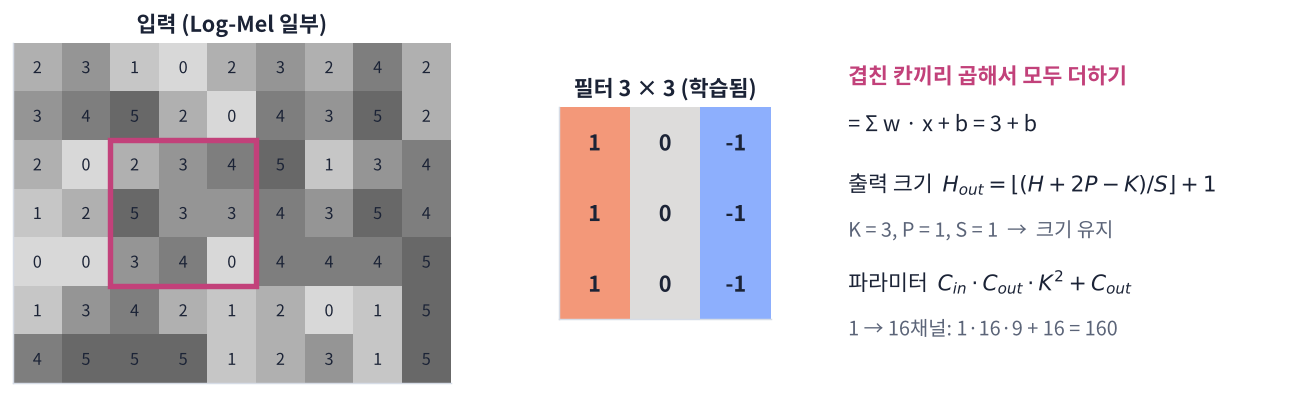

**출력 크기** (입력 $H$, 커널 $K$, 패딩 $P$, 보폭 $S$):

$$
H_{out} = \left\lfloor \frac{H + 2P - K}{S} \right\rfloor + 1
$$

$K = 3, P = 1, S = 1$이면 $H_{out} = H$ (크기 유지). 그 뒤 **MaxPool(2)** 가 $2 \times 2$ 칸 중 최댓값만 남겨 크기를 절반으로 줄입니다.

**파라미터 수**: 필터 가중치 + 편향

$$
\#\text{params}_{\text{conv}} = C_{in} \cdot C_{out} \cdot K^2 + C_{out}, \qquad
\#\text{params}_{\text{linear}} = d_{in} \cdot d_{out} + d_{out}
$$

> 🎬 **애니메이션 D5-4:** [합성곱](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#conv) — 3×3 필터가 Log-Mel 위를 미끄러지며 곱해서 더하는 과정, K · P · S를 바꿔 출력 크기 계산

### 3-2. 오늘의 모델: KWSNet

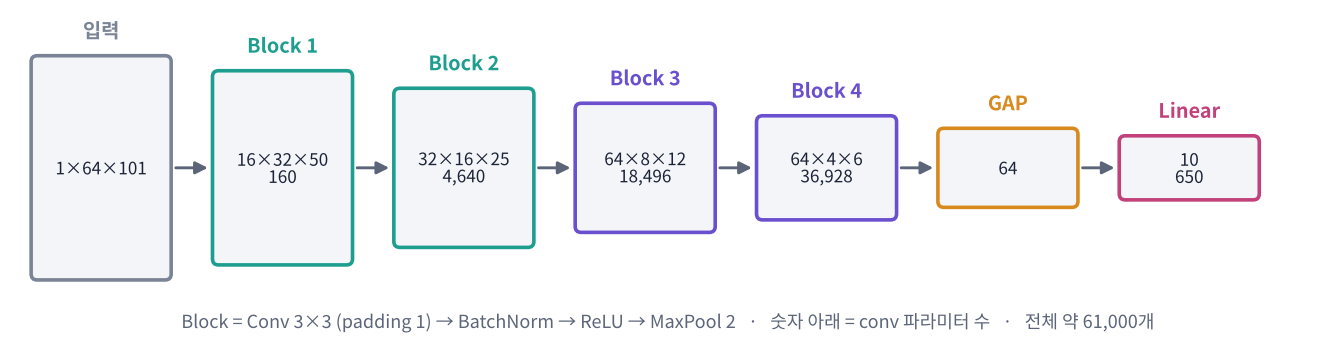

| 층 | 출력 모양 | 파라미터 |
|---|---|---|
| 입력 | $(1, 64, 101)$ | |
| Block 1: Conv 3×3 (1→16) + BN + ReLU + MaxPool 2 | $(16, 32, 50)$ | $1\cdot16\cdot9 + 16 = 160$ (+BN 32) |
| Block 2: Conv 3×3 (16→32) … | $(32, 16, 25)$ | $16\cdot32\cdot9 + 32 = 4{,}640$ (+64) |
| Block 3: Conv 3×3 (32→64) … | $(64, 8, 12)$ | $32\cdot64\cdot9 + 64 = 18{,}496$ (+128) |
| Block 4: Conv 3×3 (64→64) … | $(64, 4, 6)$ | $64\cdot64\cdot9 + 64 = 36{,}928$ (+128) |
| Global Average Pooling | $(64,)$ | 0 |
| Dropout 0.3 + Linear (64→10) | $(10,)$ | $64\cdot10 + 10 = 650$ |

- **BatchNorm(BN)**: 배치마다 값의 평균 · 분산을 맞춰 학습을 안정시킴 (채널당 2개 파라미터)
- **ReLU**: $\max(0, x)$. 음수를 0으로 → 비선형성
- **Global Average Pooling**: 채널마다 $4 \times 6$ 칸의 평균 하나 → 입력 길이가 조금 달라도 동작
- **Dropout**: 학습 중 일부 값을 무작위로 0으로 → 특정 특징에 과하게 기대지 않게

총 약 **6만 개** 파라미터. 휴대폰에서도 실시간으로 돌릴 수 있는 크기입니다.

> 🎬 **애니메이션 D5-5:** [모델 구조와 모양 추적](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#net) — 층을 하나씩 눌러 출력 모양과 파라미터 수가 어떻게 계산되는지 보기

### 🧩 빈칸 실습 4: 마지막 층 완성하기
마지막 `Linear` 층은 64개 특징을 받아 **클래스 수만큼** 점수(logit)를 내야 합니다.

In [ ]:
# 🧩 빈칸 실습 4
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class KWSNet(nn.Module):
    def __init__(self, n_classes=len(KEYWORDS)):
        super().__init__()
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 64))
        self.pool = nn.AdaptiveAvgPool2d(1)          # Global Average Pooling
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(64, ____)
    def forward(self, x):                            # x: (B, 1, 64, 101)
        x = self.features(x)                         # (B, 64, 4, 6)
        x = self.pool(x).flatten(1)                  # (B, 64)
        return self.fc(self.drop(x))                 # (B, n_classes) = logits

model = KWSNet().to(DEVICE)
out = model(xb[:2].to(DEVICE))
n_params = sum(p.numel() for p in model.parameters())
print("출력 모양:", tuple(out.shape), "| 전체 파라미터:", f"{n_params:,}")
check(tuple(out.shape) == (2, len(KEYWORDS)), hint="클래스 수는 n_classes (= 10)입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
self.fc = nn.Linear(64, n_classes)
```

**해설**: 마지막 층의 출력 개수 = 클래스 수. 이 10개의 숫자를 **logit**(점수)이라 부르고, 가장 큰 칸이 모델의 예측입니다. 숫자 10을 직접 써도 동작하지만, 키워드를 12개로 늘리면 고칠 곳이 생기므로 인자 `n_classes`를 씁니다. 전체 파라미터는 약 61,000개입니다.

</details>

In [ ]:
# ▶️ 수식 검증 1: 출력 크기 공식과 파라미터 공식이 실제와 같은지 (forward hook으로 층마다 모양 추적)
def out_size(h, k=3, p=1, s=1):
    return (h + 2 * p - k) // s + 1

shapes = []
hooks = [m.register_forward_hook(lambda m, i, o, n=n: shapes.append((n, tuple(o.shape[1:]))))
         for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.AdaptiveAvgPool2d, nn.Linear))]
model.eval()
with torch.no_grad(): model(xb[:1].to(DEVICE))
for h in hooks: h.remove()
for n, s in shapes: print(f"{n:22s} → {s}")

h, w = 64, 101
for i in range(4):
    h, w = out_size(h) // 2, out_size(w) // 2          # conv(크기 유지) → pool(절반, 버림)
print(f"\n공식으로 계산한 마지막 특징 지도: (64, {h}, {w})")

conv_params = lambda ci, co, k=3: ci * co * k * k + co
pred_params = sum(conv_params(ci, co) + 2 * co for ci, co in [(1, 16), (16, 32), (32, 64), (64, 64)]) + 64 * 10 + 10
print(f"파라미터 공식 합계 {pred_params:,} | 실제 {n_params:,}")

### 3-3. 📐 수식으로 보기: softmax와 cross-entropy

모델이 낸 10개의 logit $z_1, \dots, z_{10}$을 **확률**로 바꾸는 것이 softmax입니다.

$$
p_k = \frac{e^{z_k}}{\sum_{j} e^{z_j}}, \qquad \sum_k p_k = 1
$$

- $e^{z}$는 항상 양수 → 확률이 음수가 되지 않음
- 큰 logit일수록 지수적으로 커져서 가장 큰 칸이 확률을 대부분 가져감

**손실(loss)** 은 "정답 클래스 $y$의 확률이 얼마나 낮은가"입니다 (**cross-entropy**).

$$
\mathcal{L} = -\log p_y
$$

$p_y = 1$이면 손실 0, $p_y = 0.1$이면 $2.30$, $p_y = 0.01$이면 $4.61$. 정답을 확신 있게 틀릴수록 크게 벌을 줍니다. 처음 학습 전 모델은 10개를 고르게 찍으므로 $\mathcal{L} \approx -\log(1/10) = 2.30$에서 시작합니다.

**기울기**(놀라울 만큼 단순): $\dfrac{\partial \mathcal{L}}{\partial z_k} = p_k - \mathbb{1}[k = y]$. 정답 칸은 확률을 올리는 쪽으로, 나머지는 내리는 쪽으로 밀어 줍니다.

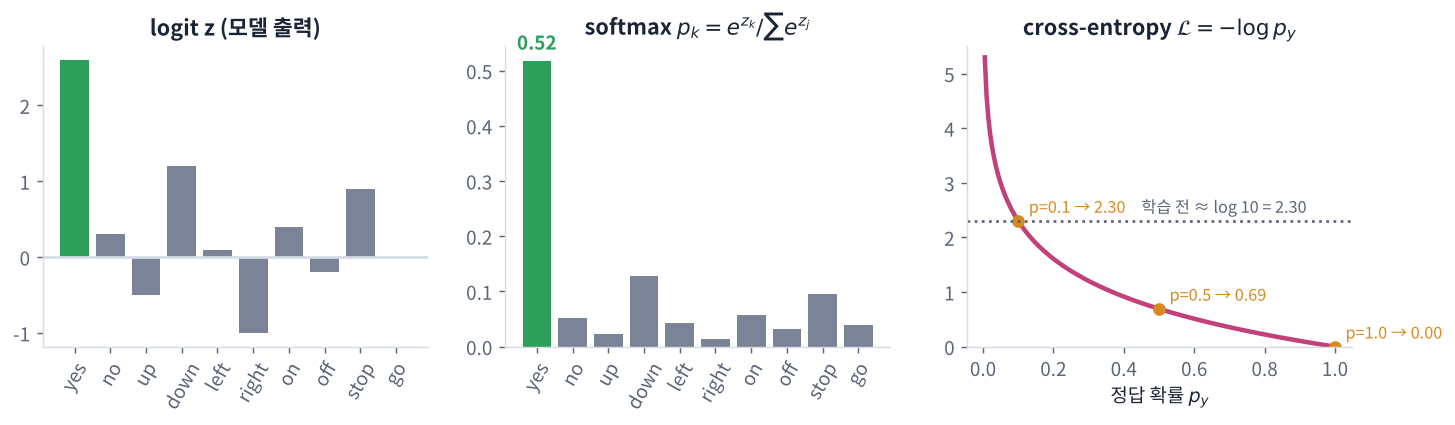

> 🎬 **애니메이션 D5-6:** [softmax와 cross-entropy](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#softmax) — logit 막대를 끌어 확률과 손실이 어떻게 바뀌는지, 정답 칸을 바꿔 보기

### 🧩 빈칸 실습 5: softmax 직접 구현
분모는 **클래스 방향**(각 행 안에서)으로 더해야 합니다. logit 모양이 `(B, 10)`이면 어느 차원일까요?

In [ ]:
# 🧩 빈칸 실습 5
z = torch.tensor([[2.0, 1.0, 0.1, -1.0], [0.5, 0.5, 0.5, 0.5]])      # (B=2, 클래스 4개)
y = torch.tensor([0, 3])                                             # 정답

probs = torch.exp(z) / torch.exp(z).sum(dim=____, keepdim=True)
ce = -torch.log(probs[torch.arange(len(y)), y]).mean()

print("직접 만든 softmax:\n", probs.numpy().round(3), "\n행 합:", probs.sum(1).numpy())
print(f"직접 만든 CE {ce:.4f} | F.cross_entropy {F.cross_entropy(z, y):.4f}")

zg = z.clone().requires_grad_(True)
F.cross_entropy(zg, y, reduction="sum").backward()
print("autograd 기울기:\n", zg.grad.numpy().round(3))
print("p − onehot     :\n", (probs - F.one_hot(y, 4)).numpy().round(3))
check(torch.allclose(probs.sum(1), torch.ones(2)) and abs(ce - F.cross_entropy(z, y)) < 1e-5, hint="클래스는 두 번째 차원, dim=1입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
probs = torch.exp(z) / torch.exp(z).sum(dim=1, keepdim=True)
```

**해설**: `z`의 모양은 (배치, 클래스)라서 클래스 방향은 `dim=1`입니다. `dim=0`으로 하면 같은 클래스끼리 배치 방향으로 더해 버려 행 합이 1이 되지 않습니다. 두 번째 행처럼 logit이 모두 같으면 확률도 모두 0.25로 같습니다. 마지막 두 출력이 같다는 것은 $\partial \mathcal{L}/\partial z = p - \text{onehot}$ 식이 PyTorch의 자동 미분(autograd) 결과와 일치한다는 뜻입니다. 실제 코드에서는 수치가 안정적인 `F.cross_entropy(logits, y)`를 씁니다 (softmax와 log를 한 번에).

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day05/worksheet.html)** — 합성곱 = 곱해서 더하기, 출력 크기 공식, 파라미터 수, MaxPool, BatchNorm · ReLU · GAP · Dropout, logit · softmax · cross-entropy, 기울기 p − onehot
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 4. 학습: forward → loss → backward → step

### 4-1. 📐 수식으로 보기: 경사 하강법

모델의 모든 파라미터를 $\theta$라 하면, 손실을 줄이는 방향(기울기의 반대)으로 조금씩 움직입니다.

$$
\theta \leftarrow \theta - \eta\, \nabla_\theta \mathcal{L}
$$

- $\eta$ (**학습률**, learning rate): 한 걸음의 크기. 너무 작으면 느리고, 너무 크면 골짜기를 넘어가 발산
- **미니배치**: 전체 데이터 대신 128개씩 손실을 계산해 한 걸음 (빠르고, 약간의 무작위성이 오히려 도움)
- **epoch**: 학습 데이터를 한 바퀴 다 보는 것
- **Adam**: 파라미터마다 걸음 크기를 자동으로 조절하는 경사 하강법. 대부분 $\eta = 10^{-3}$에서 잘 시작

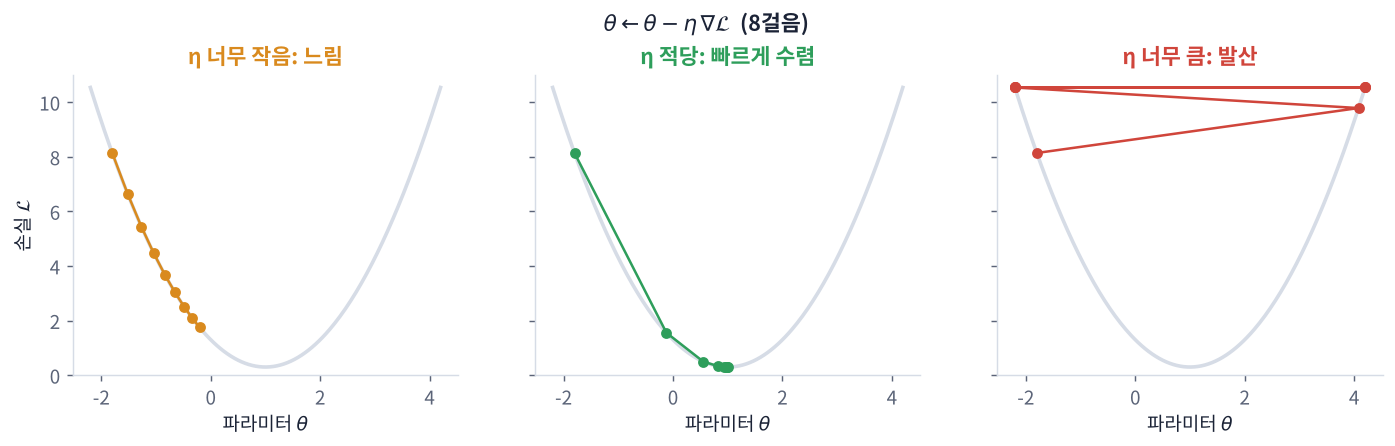

**한 걸음(step)의 네 줄**

| 순서 | 코드 | 하는 일 |
|---|---|---|
| 1 | `logits = model(xb)` | **forward**: 예측 점수 계산 |
| 2 | `loss = F.cross_entropy(logits, yb)` | 손실 계산 |
| 3 | `opt.zero_grad(); loss.backward()` | 지난 기울기를 지우고, **backward**: 모든 파라미터의 기울기 계산 |
| 4 | `opt.step()` | $\theta \leftarrow \theta - \eta \nabla\mathcal{L}$ 실행 |

> 🎬 **애니메이션 D5-7:** [경사 하강법과 학습 곡선](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#train) — 학습률을 바꿔 공이 골짜기로 내려가는 모습, 과적합이 생기는 학습 곡선 보기

### 🧩 빈칸 실습 6: 학습 루프 완성하기
기울기를 **계산하는** 메서드와, 그 기울기로 파라미터를 **움직이는** 메서드를 채우세요.

In [ ]:
# 🧩 빈칸 실습 6
def train_one_epoch(model, loader, opt, augment=None):
    model.train()                                       # Dropout · BatchNorm을 학습 모드로
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        if augment is not None:
            xb = augment(xb)                            # Part 6에서 사용
        logits = model(xb)                              # 1. forward
        loss = F.cross_entropy(logits, yb)              # 2. loss
        opt.zero_grad()
        loss.____()                                     # 3. backward: 기울기 계산
        opt.____()                                      # 4. 파라미터 업데이트
        loss_sum += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

@torch.no_grad()
def evaluate(model, loader):
    model.eval()                                        # Dropout 끄기, BatchNorm은 저장된 통계 사용
    total, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        loss_sum += F.cross_entropy(logits, yb, reduction="sum").item()
        correct += (logits.argmax(1) == yb).sum().item(); total += len(yb)
    return loss_sum / total, correct / total

def fit(model, epochs=EPOCHS, lr=1e-3, augment=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = train_one_epoch(model, train_loader, opt, augment)
        vl, va = evaluate(model, val_loader)
        for k, v in zip(hist, (tl, ta, vl, va)): hist[k].append(v)
        print(f"epoch {ep:2d} | train loss {tl:.3f} acc {ta:.1%} | val loss {vl:.3f} acc {va:.1%} | {time.time() - t0:.1f}s")
    return hist

torch.manual_seed(0)
model = KWSNet().to(DEVICE)
print(f"학습 전 val: loss {evaluate(model, val_loader)[0]:.3f} (예상 ≈ -log(1/10) = {np.log(10):.3f})")
hist = fit(model)
check(hist["train_loss"][-1] < hist["train_loss"][0] and hist["val_acc"][-1] > 0.5, hint="loss.backward(), opt.step()")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
loss.backward()
opt.step()
```

**해설**: `backward()`는 손실에서 거꾸로 거슬러 올라가며(역전파) 모든 파라미터의 $\partial \mathcal{L} / \partial \theta$를 `.grad`에 채웁니다. `step()`은 그 기울기로 $\theta \leftarrow \theta - \eta \nabla \mathcal{L}$을 실행합니다(Adam은 걸음 크기를 자동 조절). `zero_grad()`를 빼면 기울기가 배치마다 **누적**되어 학습이 엉망이 됩니다. GPU에서 12 epoch이면 검증 정확도가 보통 90% 안팎까지 오릅니다.

</details>

#### 🔍 코드 해설: 학습 루프

| 코드 | 하는 일 |
|---|---|
| `model.train() / model.eval()` | Dropout과 BatchNorm은 학습 · 평가에서 다르게 동작. 평가할 때 `eval()`을 잊으면 결과가 흔들림 |
| `@torch.no_grad()` | 평가 중에는 기울기를 계산하지 않음 → 빠르고 메모리 절약 |
| `.to(DEVICE)` | 데이터와 모델이 **같은 장치**(GPU 또는 CPU)에 있어야 계산 가능 |
| `logits.argmax(1)` | 클래스 방향에서 가장 큰 점수의 번호 = 예측 |
| `loss.item() * len(yb)` | 배치 평균 손실 × 배치 크기 → epoch 전체 평균을 정확히 구하려고 |

In [ ]:
# 학습 곡선: 손실과 정확도
ep = range(1, len(hist["train_loss"]) + 1)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
axs[0].plot(ep, hist["train_loss"], "o-", label="train"); axs[0].plot(ep, hist["val_loss"], "o-", label="val"); axs[0].set_title("loss"); axs[0].legend()
axs[1].plot(ep, hist["train_acc"], "o-", label="train"); axs[1].plot(ep, hist["val_acc"], "o-", label="val"); axs[1].set_title("accuracy"); axs[1].legend()
for ax in axs: ax.set_xlabel("epoch")
plt.tight_layout(); plt.show()
gap = hist["train_acc"][-1] - hist["val_acc"][-1]
print(f"마지막 epoch: train {hist['train_acc'][-1]:.1%} · val {hist['val_acc'][-1]:.1%} → 차이 {gap:+.1%}" + ("  (차이가 크면 과적합 신호)" if gap > 0.05 else ""))

### 4-2. 학습 곡선 읽는 법

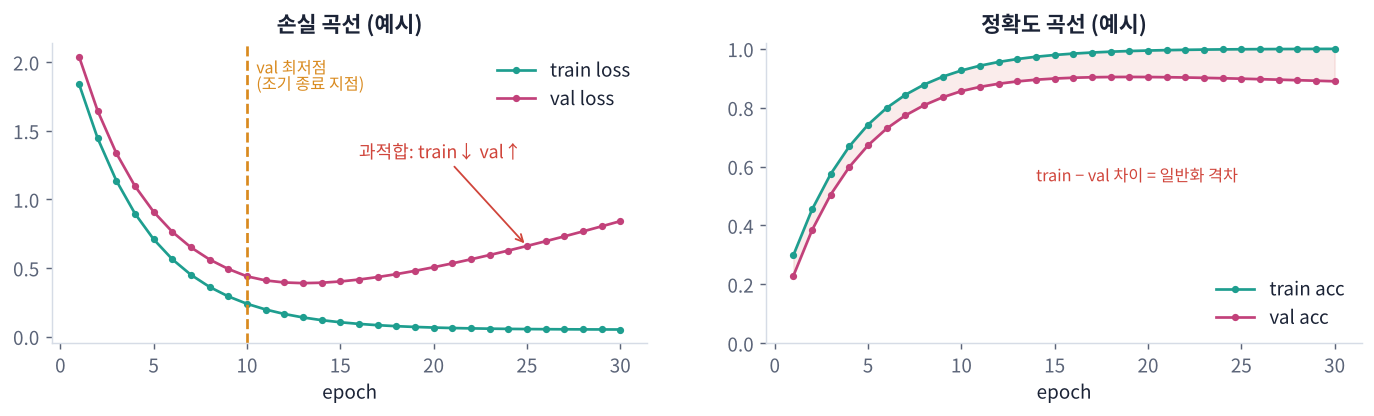

| 모양 | 뜻 | 대응 |
|---|---|---|
| train · val 손실이 같이 내려감 | 잘 배우는 중 | epoch 더 |
| train은 계속 내려가는데 val은 다시 올라감 | **과적합**: 학습 데이터를 외우는 중 | 데이터 증강, Dropout, 조기 종료 |
| 둘 다 높은 채로 멈춤 | **과소적합**: 모델이 너무 작거나 학습률이 맞지 않음 | 모델 키우기, 학습률 조정 |
| 손실이 튀거나 NaN | 학습률이 너무 큼 | $\eta$ 줄이기 |

## Part 5. 평가: 정확도와 혼동 행렬

학습에 쓰지 않은 **테스트 세트**(처음 보는 화자들)로 최종 성능을 잽니다. 검증 세트는 학습 중 설정을 고르는 데 이미 썼으므로, 마지막 성적표는 테스트 세트로 냅니다.

### 5-1. 📐 수식으로 보기: 혼동 행렬과 정밀도 · 재현율

**혼동 행렬** $C$: 행 = 정답, 열 = 예측. $C[i, j]$ = 정답이 $i$인데 $j$로 예측한 개수. 대각선이 맞힌 것입니다.

$$
\text{accuracy} = \frac{\sum_i C[i,i]}{\sum_{i,j} C[i,j]}, \qquad
\text{precision}_k = \frac{C[k,k]}{\sum_i C[i,k]}, \qquad
\text{recall}_k = \frac{C[k,k]}{\sum_j C[k,j]}
$$

- **정밀도**(precision): "모델이 *stop*이라고 한 것 중 진짜 *stop*의 비율" → 열 기준
- **재현율**(recall): "진짜 *stop* 중 모델이 *stop*이라고 맞힌 비율" → 행 기준
- **F1** $= 2PR/(P+R)$: 둘의 조화 평균

음성 비서의 깨우기 단어(wake word)라면 **오작동(정밀도)** 과 **놓침(재현율)** 중 무엇이 더 나쁜지에 따라 기준을 고릅니다.

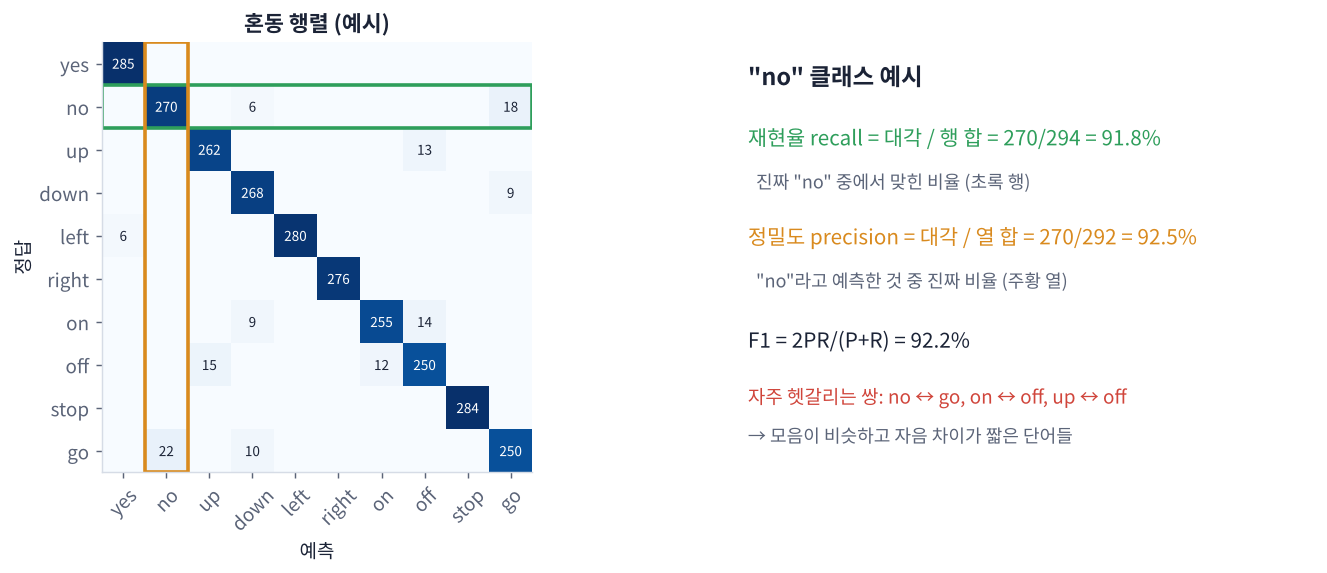

> 🎬 **애니메이션 D5-8:** [혼동 행렬](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#confusion) — 칸을 눌러 정밀도 · 재현율이 어떻게 계산되는지, 자주 헷갈리는 단어 쌍 보기

### 🧩 빈칸 실습 7: 예측 번호 꺼내기
logit 모양이 `(B, 10)`일 때, 각 샘플에서 가장 큰 점수의 **클래스 번호**를 꺼내세요.

In [ ]:
# 🧩 빈칸 실습 7
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, trues = [], []
    for xb, yb in loader:
        logits = model(xb.to(DEVICE))
        preds.append(logits.argmax(dim=____).cpu()); trues.append(yb)
    return torch.cat(preds).numpy(), torch.cat(trues).numpy()

pred, true = predict_all(model, test_loader)
n = len(KEYWORDS)
C = np.zeros((n, n), int)
for t, p in zip(true, pred): C[t, p] += 1
acc = np.trace(C) / C.sum()
print(f"테스트 정확도: {acc:.1%} ({np.trace(C)}/{C.sum()})")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(C, cmap="Blues"); plt.colorbar(im, ax=ax)
ax.set_xticks(range(n)); ax.set_xticklabels(KEYWORDS, rotation=45); ax.set_yticks(range(n)); ax.set_yticklabels(KEYWORDS)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"confusion matrix (test acc {acc:.1%})")
for i in range(n):
    for j in range(n):
        if C[i, j]: ax.text(j, i, C[i, j], ha="center", va="center", fontsize=8, color="white" if C[i, j] > C.max() / 2 else "black")
plt.tight_layout(); plt.show()
check(pred.shape == true.shape and acc > 0.5, hint="클래스 방향은 dim=1입니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
preds.append(logits.argmax(dim=1).cpu())
```

**해설**: 빈칸 5의 softmax와 같은 이유로 클래스 방향은 `dim=1`입니다. softmax는 순서를 바꾸지 않으므로(가장 큰 logit이 가장 큰 확률) 예측만 필요하면 softmax 없이 logit에서 바로 argmax합니다. `.cpu()`는 GPU 텐서를 numpy로 바꾸기 전에 CPU로 옮기는 것입니다. 혼동 행렬에서 대각선 밖의 큰 숫자가 '헷갈리는 쌍'입니다.

</details>

In [ ]:
# ▶️ 수식 검증 2: 클래스별 정밀도 · 재현율 · F1, 가장 헷갈린 쌍
P = np.diag(C) / np.maximum(C.sum(0), 1)
R = np.diag(C) / np.maximum(C.sum(1), 1)
F1 = 2 * P * R / np.maximum(P + R, 1e-9)
print(f"{'word':>6s} {'precision':>9s} {'recall':>7s} {'F1':>6s}")
for k in range(n):
    print(f"{KEYWORDS[k]:>6s} {P[k]:9.1%} {R[k]:7.1%} {F1[k]:6.1%}")
print(f"\n정확도 = 대각합 / 전체 = {np.trace(C) / C.sum():.1%}")

off = [(C[i, j], KEYWORDS[i], KEYWORDS[j]) for i in range(n) for j in range(n) if i != j]
print("가장 많이 헷갈린 쌍 (정답 → 예측):", [f"{a}→{b} {c}개" for c, a, b in sorted(off, reverse=True)[:4]])

In [ ]:
# 틀린 예를 직접 들어 보기
wrong = np.where(pred != true)[0]
print(f"틀린 테스트 샘플 {len(wrong)}개 중 3개:")
for i in wrong[:3]:
    path = test_items[i][0]
    print(f"  정답 {KEYWORDS[true[i]]:>5s} → 예측 {KEYWORDS[pred[i]]:>5s}"); display(Audio(load_1s(path), rate=SR))

---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day05/worksheet.html)** — 경사 하강법과 학습률, epoch · 미니배치, forward → loss → backward → step, zero_grad, train/eval 모드, 학습 곡선과 과적합, 테스트 정확도, 혼동 행렬, 정밀도 · 재현율 · F1
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 6. 성능 높이기: SpecAugment, 그리고 미니 프로젝트

### 6-1. 📐 수식으로 보기: SpecAugment

**SpecAugment**(Google, 2019)는 Log-Mel 이미지의 일부를 **가려서**(mask) 학습시키는 데이터 증강입니다. 모델이 특정 주파수 띠나 특정 순간 하나에만 기대지 않고, 여러 단서를 함께 보게 만듭니다. Whisper를 포함한 대부분의 최신 음성 인식 모델이 씁니다.

- **주파수 마스크**: 폭 $f \sim U[0, F]$, 시작 $f_0 \sim U[0, 64 - f)$ → 행 $[f_0, f_0 + f)$를 가림
- **시간 마스크**: 폭 $t \sim U[0, T_m]$, 시작 $t_0 \sim U[0, 101 - t)$ → 열 $[t_0, t_0 + t)$를 가림

$$
\tilde{X}[m, \tau] =
\begin{cases}
\text{(가림 값)} & f_0 \le m < f_0 + f \;\text{또는}\; t_0 \le \tau < t_0 + t \\
X[m, \tau] & \text{그 외}
\end{cases}
$$

학습할 때만 적용하고, 평가 · 예측할 때는 쓰지 않습니다. 정규화된 입력에서는 가림 값 0이 곧 '평균값'입니다.

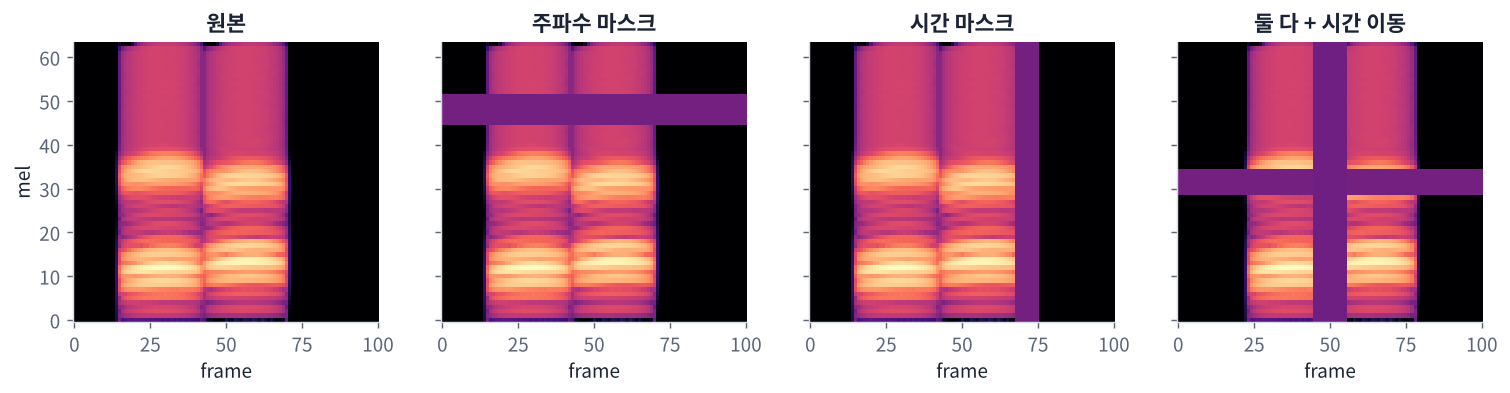

> 🎬 **애니메이션 D5-9:** [SpecAugment](https://imguru-mooc.github.io/AI_Voice/day05/animation.html#specaug) — 주파수 · 시간 마스크 폭과 개수를 바꿔 가며 가려진 Log-Mel 보기

In [ ]:
SPEC_AUG = nn.Sequential(
    T.FrequencyMasking(freq_mask_param=8),      # 최대 8개 mel 줄 가리기
    T.TimeMasking(time_mask_param=12),          # 최대 12 프레임(120 ms) 가리기
).to(DEVICE)

AUG_CALLS = 0
def augment(xb):
    global AUG_CALLS; AUG_CALLS += 1
    xb = SPEC_AUG(xb)
    shift = random.randint(-10, 10)             # ±100 ms 시간 이동
    return torch.roll(xb, shifts=shift, dims=-1)

fig, axs = plt.subplots(1, 4, figsize=(15, 2.8))
x0 = xb[:1].to(DEVICE)
for ax, title in zip(axs, ["original", "aug 1", "aug 2", "aug 3"]):
    img = x0 if title == "original" else augment(x0.clone())
    ax.imshow(img[0, 0].cpu(), origin="lower", aspect="auto", cmap="magma"); ax.set_title(title)
plt.tight_layout(); plt.show()

### 🧩 빈칸 실습 8: 증강을 켜고 다시 학습하기
`fit()`에 증강 함수를 넘겨 같은 epoch 동안 학습하고, 앞의 모델(증강 없음)과 비교하세요.

In [ ]:
# 🧩 빈칸 실습 8
torch.manual_seed(0)
model_aug = KWSNet().to(DEVICE)
hist_aug = fit(model_aug, augment=____)

base_test = evaluate(model, test_loader)[1]
aug_test = evaluate(model_aug, test_loader)[1]
print(f"\n테스트 정확도: 증강 없음 {base_test:.1%} → SpecAugment {aug_test:.1%}")
print(f"train − val 차이: 증강 없음 {hist['train_acc'][-1] - hist['val_acc'][-1]:+.1%} → SpecAugment {hist_aug['train_acc'][-1] - hist_aug['val_acc'][-1]:+.1%}")
check(len(hist_aug["train_acc"]) == EPOCHS and AUG_CALLS >= EPOCHS * len(train_loader), hint="위에서 만든 함수 이름 augment를 넘깁니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
hist_aug = fit(model_aug, augment=augment)
```

**해설**: 증강을 켜면 학습 데이터가 매번 조금씩 다르게 보여서 **학습 정확도는 조금 낮아지고**, 학습 · 검증 차이(과적합)가 줄어듭니다. 같은 epoch 수에서는 테스트 정확도가 비슷하거나 조금 오르고, epoch를 더 늘리면 차이가 커지는 경우가 많습니다. 실행할 때마다 결과가 조금 다를 수 있으니 **차이가 작으면 '비슷하다'** 로 읽으세요.

</details>

### 6-2. 미니 프로젝트: `predict_keyword()` — 아무 음성 파일이나 넣으면 키워드를 맞히는 함수

실전 입력은 1초짜리로 깔끔하게 잘려 있지 않습니다. 그래서 학습 데이터와 **똑같은 모양으로 맞추는 전처리**가 핵심입니다.

| 단계 | 하는 일 | 연결 |
|---|---|---|
| 1 | 16 kHz mono로 읽기 | D2 |
| 2 | 앞뒤 무음 자르기 → 가장 큰 부분을 중심으로 1초 만들기 | D4 |
| 3 | Log-Mel (1 × 64 × 101) | D3, Part 2 |
| 4 | **학습 세트의 μ, σ로 정규화** | Part 2 |
| 5 | 모델 → softmax → 상위 3개 | Part 3 |

### 🧩 빈칸 실습 9: predict_keyword() 완성하기
학습할 때와 **같은 정규화**를 해야 합니다. 빼는 값은 무엇일까요?

In [ ]:
# 🧩 빈칸 실습 9
def center_1s(y):
    y, _ = librosa.effects.trim(y, top_db=30)                       # 앞뒤 무음 제거
    if len(y) <= SR:
        return pad_or_trim(np.pad(y, ((SR - len(y)) // 2, 0)))      # 가운데 정렬
    e = np.convolve(y ** 2, np.ones(SR), "valid")                   # 1초 창마다 에너지
    s = int(np.argmax(e)); return y[s:s + SR]                       # 가장 큰 1초

@torch.no_grad()
def predict_keyword(path, model, topk=3):
    y, _ = librosa.load(path, sr=SR, mono=True)
    x = (wav2feat(center_1s(y)) - ____) / SD                       # 학습 때와 같은 정규화
    model.eval()
    p = F.softmax(model(x.unsqueeze(0).to(DEVICE)), dim=1)[0].cpu()
    top = p.topk(topk)
    return [(KEYWORDS[i], float(v)) for v, i in zip(top.values, top.indices)]

# 테스트 세트 파일 하나로 먼저 확인
path, c, _ = test_items[0]
res = predict_keyword(path, model_aug)
print("정답:", KEYWORDS[c], "| 예측 top-3:", [(w, f"{v:.1%}") for w, v in res])
check(abs(sum(v for _, v in predict_keyword(path, model_aug, topk=10)) - 1) < 1e-4 and res[0][1] >= res[1][1],
      hint="학습 세트 평균 MU를 뺍니다.")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
x = (wav2feat(center_1s(y)) - MU) / SD
```

**해설**: 모델은 $(x - \mu)/\sigma$로 정규화된 입력만 보고 학습했습니다. 예측할 때 정규화를 빼먹거나 **다른** $\mu, \sigma$를 쓰면 입력 분포가 달라져 성능이 크게 떨어집니다. 그래서 모델을 저장할 때 $\mu, \sigma$와 키워드 목록을 **함께** 저장합니다 (아래 셀). 실무에서 '학습할 땐 잘 됐는데 배포하니 안 된다'의 가장 흔한 원인이 이 전처리 불일치입니다.

</details>

In [ ]:
# 처음 보는 '목소리'로 시험: gTTS(영어)로 키워드를 합성해 넣어 보기
from gtts import gTTS

rows = []
for w in ["yes", "no", "stop", "go", "left", "right"]:
    gTTS(w, lang="en").save(f"kw_{w}.mp3")
    res = predict_keyword(f"kw_{w}.mp3", model_aug)
    rows.append((w, res))
    print(f"{w:>5s} → {res[0][0]:>5s} ({res[0][1]:.0%}) {'✅' if res[0][0] == w else '❌'}   2위 {res[1][0]} ({res[1][1]:.0%})")
display(Audio("kw_yes.mp3"))
print("\n※ TTS 목소리는 학습 데이터(사람 녹음)와 달라서 틀리는 단어가 있을 수 있습니다. 왜 틀렸는지 2위를 보고 생각해 보세요.")

> 🎙️ **내 목소리로 해 보기 (선택)**: 휴대폰으로 "yes", "stop" 등을 녹음해 업로드한 뒤 `predict_keyword("파일이름", model_aug)`를 실행하세요.
>
> ```python
> from google.colab import files
> up = files.upload()                       # 파일 선택 창
> for name in up: print(name, predict_keyword(name, model_aug))
> ```

In [ ]:
# 모델 저장하기: 가중치 + 전처리에 필요한 값(μ, σ, 키워드, 설정)을 함께
torch.save({"state_dict": model_aug.state_dict(), "keywords": KEYWORDS, "mu": MU, "sd": SD,
            "n_mels": N_MELS, "n_fft": N_FFT, "hop": HOP}, "kws_cnn.pt")
print(f"저장: kws_cnn.pt ({os.path.getsize('kws_cnn.pt') / 1024:.0f} KB)")

ckpt = torch.load("kws_cnn.pt", map_location=DEVICE)
loaded = KWSNet(len(ckpt["keywords"])).to(DEVICE); loaded.load_state_dict(ckpt["state_dict"])
print("다시 불러온 모델 테스트 정확도:", f"{evaluate(loaded, test_loader)[1]:.1%}")

#### 🔍 코드 해설: predict_keyword() · 저장

| 코드 | 하는 일 |
|---|---|
| `librosa.effects.trim(y, top_db=30)` | 가장 큰 소리보다 30 dB 이상 작은 앞뒤를 무음으로 보고 잘라 냄 (D2) |
| `np.convolve(y ** 2, np.ones(SR), "valid")` | 1초 창을 밀며 에너지 합 → 가장 큰 1초를 고름 (긴 녹음 대비) |
| `(wav2feat(...) - MU) / SD` | 학습 세트 기준 정규화. **학습과 예측의 전처리는 반드시 같아야** 함 |
| `F.softmax(..., dim=1)[0]` | 확률로 바꾸고 배치 차원 제거 |
| `p.topk(3)` | 확률 상위 3개의 값과 번호 |
| `torch.save({"state_dict": ..., "mu": ..., ...})` | 가중치만이 아니라 전처리 값까지 한 파일에. 약 250 KB |

---
### 📝 4교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day05/worksheet.html)** — SpecAugment(주파수 · 시간 마스크), 학습 때만 증강, 과적합 줄이기, 예측 전처리 일치(μ · σ), center_1s, softmax top-k, 모델 저장 · 불러오기
>
> 10문항을 풀고 **채점하기**를 누르세요. 결과 코드와 해설이 나옵니다. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다. 4교시까지 마쳤다면 아래 Part 7의 **제출 방법**을 따라 노션에 제출하세요.

## Part 7. 정리 & 과제

### 오늘 배운 것
| 개념 | 핵심 | 수식 · 코드 |
|---|---|---|
| Speech Commands | 1초 · 16 kHz · 35단어, 화자 기준 분할 | `torchaudio.datasets.SPEECHCOMMANDS` |
| 1초 맞추기 | 짧으면 0 채우기, 길면 자르기 | `np.pad(y, (0, n - len(y)))` |
| 입력 특징 | Log-Mel 64 × 101 | $M = 1 + \lfloor 16000/160 \rfloor = 101$ |
| 정규화 | 학습 세트 기준, 예측에도 같은 값 | $\hat x = (x - \mu)/\sigma$ |
| 합성곱 | 필터와 곱해서 더하기 | $y = b + \sum w \cdot x$ |
| 출력 크기 | 커널 · 패딩 · 보폭 | $\lfloor (H + 2P - K)/S \rfloor + 1$ |
| 파라미터 수 | conv · linear | $C_{in} C_{out} K^2 + C_{out}$, $d_{in} d_{out} + d_{out}$ |
| softmax | 점수 → 확률 | $p_k = e^{z_k} / \sum_j e^{z_j}$ |
| cross-entropy | 정답 확률의 −log | $\mathcal{L} = -\log p_y$, $\partial\mathcal{L}/\partial z = p - \text{onehot}$ |
| 경사 하강법 | 기울기 반대로 한 걸음 | $\theta \leftarrow \theta - \eta \nabla\mathcal{L}$ |
| 학습 루프 | 네 줄 | forward → loss → `backward()` → `step()` |
| 혼동 행렬 | 정답 × 예측 | precision = 열 기준, recall = 행 기준 |
| SpecAugment | 주파수 · 시간 가리기 | `T.FrequencyMasking`, `T.TimeMasking` |

### 📝 과제 (미니 프로젝트 보고서)
1. **키워드 바꾸기**: `KEYWORDS`를 숫자 `zero ~ nine` 10개로 바꿔 처음부터 다시 학습하고, 테스트 정확도와 혼동 행렬에서 가장 헷갈린 쌍을 보고하세요.
2. **실험 하나 고르기**: (a) `n_mels`를 40 / 64 / 80으로 바꾸기, (b) 채널 수를 반으로 / 두 배로, (c) 학습률 $10^{-2}$ / $10^{-3}$ / $10^{-4}$ 중 하나를 골라 학습 곡선 그림과 테스트 정확도를 표로 비교하세요.
3. **내 목소리 테스트**: 휴대폰으로 10개 키워드를 녹음해 `predict_keyword()`로 맞혀 보고, 틀린 단어는 왜 틀렸는지 (top-3, 녹음 환경, 발음) 두세 문장으로 쓰세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D5 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day05/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. 이름, 교시별 점수, 오답 표(내 답과 정답)가 함께 붙습니다.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day05/animation.html) — D5-1 ~ D5-9

### 다음 시간 (D6)
오늘은 **단어 10개 중 하나**를 고르는 분류였습니다. D6부터는 **어떤 문장이든 글자로 받아 적는** 음성 인식, **Whisper**로 넘어갑니다. 오늘 만든 Log-Mel · CNN · 학습 루프 개념이 Whisper의 인코더를 이해하는 바탕이 됩니다.